# PeakWise · Exploring the RECON-SL smart-meter data

**What we do.** Look at the raw 15-minute readings of a few households, at missing data, and at the evening target (18:30–22:30), before any modelling.

**Why.** To understand what a meter reading is and what the target looks like, so that the later feature and validation choices make sense.

**Scope.** No model training and no re-run of the 45-million-row audit. The notebook reads raw rows for a few households and the audited target file.

**Ground rules**
1. `importkwh` is a **cumulative register** (kWh since the meter started), not consumption.
2. A reading stamped *t* closes the interval (*t* − 15 min, *t*]; the audit established this.
3. Consumption = register(*t*) − register(*t* − 15 min), and only when both readings exist. A missing reading makes the interval *unknown*, never zero.
4. Nothing is repaired. Negative steps, resets and duplicates are counted and shown.

In [1]:
from pathlib import Path
import json
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

# --- paths (the notebook lives in <project>/notebooks/) -------------------------------------------------
PROJECT = Path.cwd().resolve()
if not (PROJECT / "data_zenodo").exists():
    PROJECT = PROJECT.parent
DATA_DIR = PROJECT / "data_zenodo/data/consumption_data/smart_meter/15min_interval"
FILES = [DATA_DIR / f"smart_15min_{k}.csv" for k in (1, 2, 3)]
AUDIT_DIR = PROJECT / "artifacts/audit"
OUT_DIR = PROJECT / "artifacts/eda"                      # figures and the small cache live here
OUT_DIR.mkdir(parents=True, exist_ok=True)
READ_COLS = ["household_ID", "date", "time", "obis", "importkwh(kwh)"]

# --- constants -------------------------------------------------------------------------------------------
INTERVAL = pd.Timedelta(minutes=15)
PEAK_START, PEAK_END = pd.Timedelta(hours=18, minutes=30), pd.Timedelta(hours=22, minutes=30)
C_PEAK, C_INK, C_MUTED = "#e8912d", "#1f3a4d", "#8a97a3"
C_HH = {"low": "#3b8ea5", "typical": "#2f2f2f", "high": "#c0392b"}

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "axes.titlesize": 12, "axes.titleweight": "bold",
                     "axes.labelsize": 10, "legend.frameon": False, "figure.constrained_layout.use": True})

def hhmm(ax, step=3):
    ax.xaxis.set_major_locator(mdates.HourLocator(interval=step))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))

def save(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png", dpi=130, bbox_inches="tight")

print("project root:", PROJECT.name)
print("raw files found:", all(f.exists() for f in FILES), "| audit folder found:", AUDIT_DIR.exists())

project root: peakwise
raw files found: True | audit folder found: True


## 0. The raw files

The three CSV files hold 45.6 million rows, too many to load at once. We read them in chunks, keep only a few households, and take the list of good households from the small audited tables.

In [2]:
head = pd.read_csv(FILES[0], usecols=READ_COLS, nrows=200_000)
print(f"first 200,000 rows of smart_15min_1.csv  ->  {head['household_ID'].nunique()} households, "
      f"dates {head['date'].min()} to {head['date'].max()} ({head['date'].nunique()} days)")
display(head.head(8))
print("\nobis values in this sample:", head["obis"].value_counts().to_dict())

first 200,000 rows of smart_15min_1.csv  ->  248 households, dates 2023-10-01 to 2023-10-12 (12 days)


,household_ID,date,time,obis,importkwh(kwh)
0,ID4827,2023-10-01,00:00:00,LP,21553.312
1,ID4336,2023-10-01,22:15:00,LP,3434.237
2,ID4338,2023-10-01,22:15:00,LP,2297.699
3,ID2420,2023-10-01,22:15:00,LP,4436.904
4,ID4333,2023-10-01,22:15:00,LP,15188.885
5,ID4329,2023-10-01,22:15:00,LP,8714.571
6,ID4341,2023-10-01,22:15:00,LP,15089.933
7,ID4325,2023-10-01,22:15:00,LP,4648.624



obis values in this sample: {'LP': 200000}


**Observed.** The register values are large and slowly growing (thousands of kWh): this is the cumulative register, not consumption. The first 200,000 rows hold only 248 of 2,938 households and 1–12 October 2023, because the file is ordered by date. They are a partial chronological sample, not a representative one, so the rest of the notebook scans all files in chunks and keeps the full histories of three households.

## Choosing households

We use the audited table `household_days_peak.csv` only to *pick* three households with a low, typical and high evening level (10th, 50th and 90th percentile of per-household median evening kWh), among those with at least 200 complete days and 200 valid evening values.

In [3]:
def read_audit_csv(path):
    """Audit CSVs may be space-padded if a spreadsheet/editor aligned them: strip that instead of trusting it."""
    d = pd.read_csv(path, skipinitialspace=True)
    d.columns = d.columns.str.strip()
    for c in d.select_dtypes("object"):
        d[c] = d[c].str.strip()
    return d

hd = read_audit_csv(AUDIT_DIR / "household_days_peak.csv")
hd["full_day"] = hd["n_readings_day"] == 96
stats = hd.groupby("household_ID").agg(
    days_with_any_reading=("date", "size"),
    days_with_96_readings=("full_day", "sum"),
    valid_evening_days=("status", lambda s: (s == "valid").sum()),
    median_evening_kwh=("peak_kwh_1830_2230", "median"))
eligible = stats[(stats.days_with_96_readings >= 200) & (stats.valid_evening_days >= 200)]

chosen = {}
for label, q in [("low", 0.10), ("typical", 0.50), ("high", 0.90)]:
    target = eligible["median_evening_kwh"].quantile(q)
    gap = (eligible["median_evening_kwh"] - target).abs()
    # nearest median; ties broken by the most complete days
    pick = eligible.assign(gap=gap).sort_values(["gap", "days_with_96_readings"], ascending=[True, False]).index[0]
    chosen[label] = pick

sel = stats.loc[list(chosen.values())].copy()
sel.insert(0, "level", list(chosen.keys()))
print(f"{len(eligible)} of {len(stats)} households meet the completeness filter")
display(sel.round(3))
HH = chosen                       # {'low': 'ID...', 'typical': 'ID...', 'high': 'ID...'}

400 of 2938 households meet the completeness filter


,level,days_with_any_reading,days_with_96_readings,valid_evening_days,median_evening_kwh
household_ID,,,,,
ID4160,low,231,204,221,0.061
ID1457,typical,244,203,231,0.725
ID4866,high,249,202,227,2.331


**Observed.** The three chosen households and their audited summaries. They are examples, not a random sample: the completeness filter keeps 400 of 2,938 households, so what we see here (for example the rarity of negative steps) may not hold for households that report only briefly.

In [4]:
# Stream all three files in chunks and keep only the selected households (cached after the first run).
CACHE = OUT_DIR / "selected_households_raw.csv.gz"
t0 = time.time()
if CACHE.exists() and set(pd.read_csv(CACHE, usecols=["household_ID"])["household_ID"]) == set(HH.values()):
    raw = pd.read_csv(CACHE, dtype=str)
    print(f"loaded cache ({len(raw):,} rows)")
else:
    parts, rows_seen, max_chunk = [], 0, 0
    for f in FILES:
        for chunk in pd.read_csv(f, usecols=READ_COLS, dtype=str, chunksize=500_000):
            rows_seen += len(chunk); max_chunk = max(max_chunk, len(chunk))
            parts.append(chunk[chunk["household_ID"].isin(HH.values())])
    raw = pd.concat(parts, ignore_index=True)
    raw.to_csv(CACHE, index=False)
    print(f"scanned {rows_seen:,} rows in {time.time()-t0:.0f}s, never holding more than {max_chunk:,} raw rows at once; "
          f"kept {len(raw):,} rows")
print(raw.groupby("household_ID").size().rename("rows kept").to_frame().T.to_string())

loaded cache (66,569 rows)
household_ID  ID1457  ID4160  ID4866
rows kept      22855   21674   22040


## Turning readings into 15-minute consumption

For each household we sort by timestamp, check (but do not fix) duplicate and off-grid times, lay the readings on a complete 15-minute grid so that a missing reading becomes `NaN`, and compute `consumption = register(t) − register(t − 15 min)`. A difference therefore exists only when two consecutive readings exist. Negative steps are flagged, not corrected.

In [5]:
raw["t"] = pd.to_datetime(raw["date"] + " " + raw["time"], format="%Y-%m-%d %H:%M:%S")
raw["reg"] = raw["importkwh(kwh)"].astype(float)
raw = raw.sort_values(["household_ID", "t"]).reset_index(drop=True)

grids, integrity = {}, []
for level, hid in HH.items():
    r = raw[raw.household_ID == hid]
    dup = int(r.duplicated("t").sum())
    on_grid = (r["t"].dt.minute % 15 == 0) & (r["t"].dt.second == 0)
    off = int((~on_grid).sum())
    assert dup == 0, f"{hid}: {dup} duplicate timestamps - decide explicitly before continuing"
    s = r[on_grid].set_index("t")["reg"]                # off-grid rows are counted above, not hidden
    idx = pd.date_range(s.index.min().normalize(), s.index.max().normalize() + pd.Timedelta(days=1), freq="15min")
    g = s.reindex(idx).to_frame("reg")
    g["present"] = g["reg"].notna()
    g["kwh"] = g["reg"].diff()                          # NaN unless this AND the previous reading exist
    g["usable"] = g["kwh"].notna() & (g["kwh"] >= 0)    # negative steps are flagged, never clipped
    g["kwh_ok"] = g["kwh"].where(g["usable"])
    start = g.index - INTERVAL
    g["day"] = start.normalize()                        # an interval belongs to the day it STARTS in
    g["start_tod"] = start - g["day"]
    g["hour"] = (g["start_tod"] // pd.Timedelta(hours=1)).astype(int)
    g["in_peak"] = (g["start_tod"] >= PEAK_START) & (g["start_tod"] < PEAK_END)
    grids[level] = g
    integrity.append({"level": level, "household": hid, "readings": len(r), "duplicate_timestamps": dup,
                      "off_grid_times": off, "obis_LP": int((r.obis == "LP").sum()), "obis_DBE": int((r.obis == "DBE").sum()),
                      "grid_slots": len(g), "readings_present": int(g.present.sum()),
                      "intervals_computable": int(g.kwh.notna().sum()),
                      "negative_steps": int((g.kwh < 0).sum()), "steps_above_10kWh": int((g.kwh > 10).sum())})
display(pd.DataFrame(integrity).set_index("level"))

# per-household daily tables: a day/hour total exists only when EVERY interval in it is usable
tables = {}
for level, g in grids.items():
    daily = g.groupby("day").agg(n_ok=("usable", "sum"), total_kwh=("kwh_ok", "sum"))
    daily.loc[daily.n_ok < 96, "total_kwh"] = np.nan
    ev = g[g.in_peak].groupby("day").agg(n_peak_ok=("usable", "sum"), evening_kwh=("kwh_ok", "sum"))
    ev.loc[ev.n_peak_ok < 16, "evening_kwh"] = np.nan
    daily = daily.join(ev)
    hourly = g.groupby(["day", "hour"]).agg(n_ok=("usable", "sum"), kwh=("kwh_ok", "sum"))
    hourly.loc[hourly.n_ok < 4, "kwh"] = np.nan
    tables[level] = {"daily": daily, "hourly": hourly}

,household,readings,duplicate_timestamps,off_grid_times,obis_LP,obis_DBE,grid_slots,readings_present,intervals_computable,negative_steps,steps_above_10kWh
level,,,,,,,,,,,
low,ID4160,21674,0,0,21674,0,40513,21674,21650,0,0
typical,ID1457,22855,0,0,22855,0,42529,22855,22810,0,0
high,ID4866,22040,0,0,22022,18,40513,22040,21987,0,0


**Observed.**
* The three households have no duplicate timestamps, no off-grid times, no negative steps and no step above the audit's 10 kWh limit. This matches the audit's 0 duplicates in all 45.6 million rows. (ID4866 has 18 `DBE` midnight rows, kept as in the audit.)
* Only about 54% of the quarter-hours in each household's observed period have a reading (for example 21,674 of 40,512 for the low household), so almost half of all intervals are unknown. Section 4 looks at this.

## 1. One household, one complete day

We take the typical household and one complete day (all 17 readings from 18:30 to 22:30) whose evening use is closest to the household's own median. The shaded band is the 18:30–22:30 window.

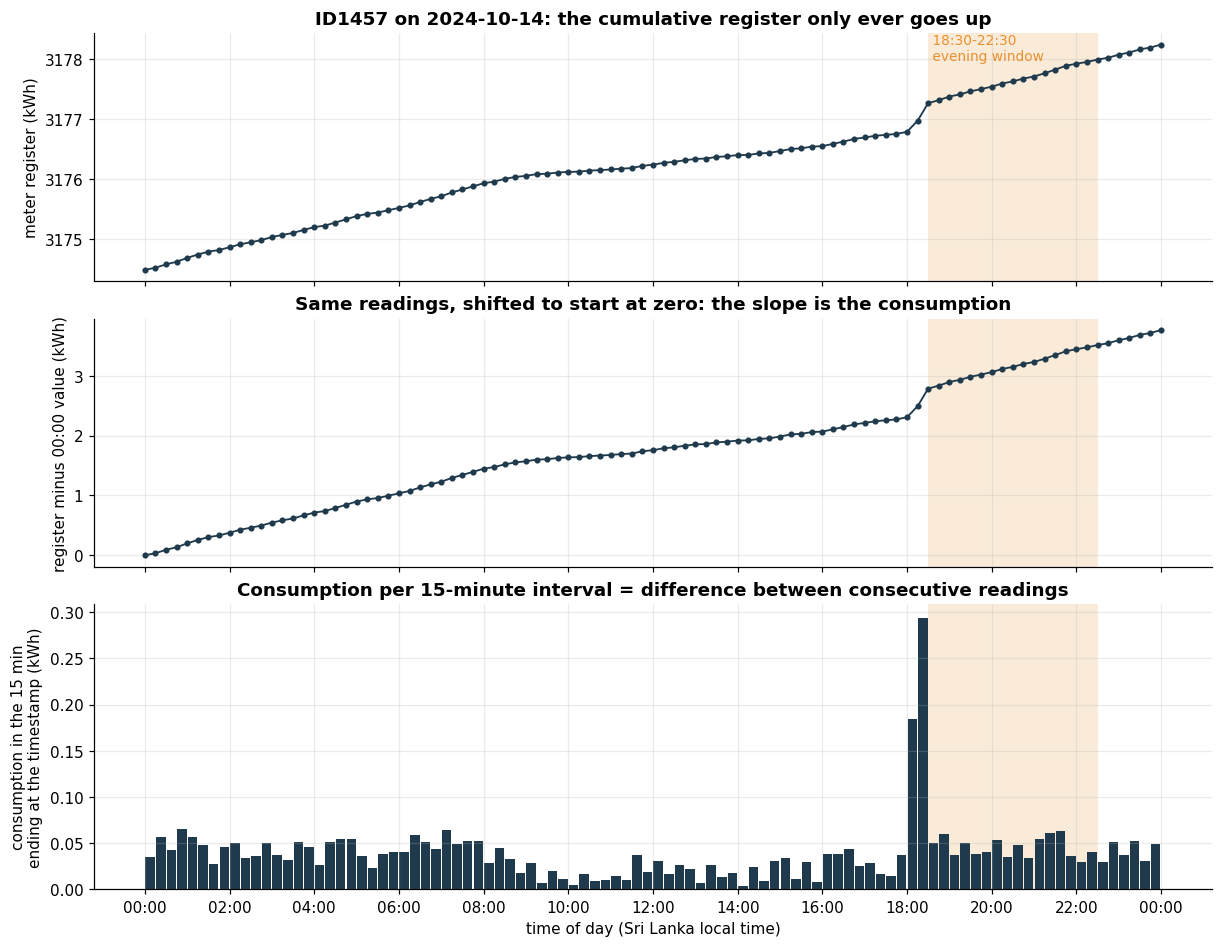

register at 00:00: 3,174.484 kWh | register at 24:00: 3,178.246 kWh | whole day: 3.762 kWh
register at 18:30: 3,177.268 kWh | register at 22:30: 3,177.996 kWh | evening = 0.728 kWh
sum of the 16 interval values between 18:30 and 22:30 = 0.728 kWh  (identical: the differences telescope)
intervals this day: 96 computable, 0 negative
three largest intervals (interval END time -> kWh): {'18:30': 0.294, '18:15': 0.184, '01:00': 0.065}
first interval inside the window ends at 18:45 and used 0.050 kWh


In [6]:
lvl = "typical"
g, daily = grids[lvl], tables[lvl]["daily"]
cand = daily[(daily.n_ok == 96) & daily.evening_kwh.notna()].copy()
median_ev = cand.evening_kwh.median()
day1 = (cand.evening_kwh - median_ev).abs().sort_values().index[0]
d = g.loc[day1: day1 + pd.Timedelta(days=1)]            # readings 00:00 ... next-day 00:00 (97 points)

fig, ax = plt.subplots(3, 1, figsize=(11, 8.5), sharex=True, height_ratios=[1, 1, 1.15])
for a in ax:
    a.axvspan(day1 + PEAK_START, day1 + PEAK_END, color=C_PEAK, alpha=0.18, lw=0)
ax[0].plot(d.index, d.reg, marker="o", ms=3, lw=1.2, color=C_INK)
ax[0].set_ylabel("meter register (kWh)")
ax[0].set_title(f"{HH[lvl]} on {day1.date()}: the cumulative register only ever goes up")
ax[1].plot(d.index, d.reg - d.reg.iloc[0], marker="o", ms=3, lw=1.2, color=C_INK)
ax[1].set_ylabel("register minus 00:00 value (kWh)")
ax[1].set_title("Same readings, shifted to start at zero: the slope is the consumption")
ax[2].bar(d.index[1:] - INTERVAL / 2, d.kwh_ok.iloc[1:], width=INTERVAL * 0.9, color=C_INK, align="center")
ax[2].set_ylabel("consumption in the 15 min\nending at the timestamp (kWh)")
ax[2].set_title("Consumption per 15-minute interval = difference between consecutive readings")
hhmm(ax[2], 2); ax[2].set_xlabel("time of day (Sri Lanka local time)")
ax[0].text(day1 + PEAK_START, ax[0].get_ylim()[1], " 18:30-22:30\n evening window", va="top", color=C_PEAK, fontsize=9)
save(fig, "01_one_household_one_day"); plt.show()

e0, e1 = d.reg.loc[day1 + PEAK_START], d.reg.loc[day1 + PEAK_END]
ev_sum = d.kwh_ok[(d.index > day1 + PEAK_START) & (d.index <= day1 + PEAK_END)].sum()
print(f"register at 00:00: {d.reg.iloc[0]:,.3f} kWh | register at 24:00: {d.reg.iloc[-1]:,.3f} kWh | whole day: {d.reg.iloc[-1]-d.reg.iloc[0]:.3f} kWh")
print(f"register at 18:30: {e0:,.3f} kWh | register at 22:30: {e1:,.3f} kWh | evening = {e1-e0:.3f} kWh")
print(f"sum of the 16 interval values between 18:30 and 22:30 = {ev_sum:.3f} kWh  (identical: the differences telescope)")
print(f"intervals this day: {int(d.kwh.iloc[1:].notna().sum())} computable, {int((d.kwh.iloc[1:] < 0).sum())} negative")
top = d.kwh_ok.iloc[1:].nlargest(3)
print("three largest intervals (interval END time -> kWh):", {f"{t:%H:%M}": round(float(v), 3) for t, v in top.items()})
print(f"first interval inside the window ends at 18:45 and used {d.kwh_ok[day1 + PEAK_START + INTERVAL]:.3f} kWh")

**Observed.** The same 97 readings of one day (ID1457, 14 October 2024), drawn as the cumulative register, the register shifted to start at 0, and the 15-minute consumption obtained by differencing.
* The register level (about 3,175 kWh) says nothing about today; only *changes* matter. The whole day moves it by 3.762 kWh, so the top line looks flat. Dividing an interval's kWh by 0.25 h gives the average power in kW.
* The 16 evening intervals add up exactly to `register(22:30) − register(18:30)` = 0.728 kWh, about 19% of the day. The target therefore needs only two readings; the audit still requires all 17 so that both belong to the same continuous counter.
* The two biggest intervals of the day (0.184 and 0.294 kWh) end at 18:15 and 18:30, just *before* the window, while the first interval inside it uses 0.050 kWh. Moving the window by one interval would change this day's value a lot, so the edge convention matters.

## 2. The same household over many days

We compute three views from complete intervals only: the average hourly pattern, total use per day, and evening use per day with its share of the day. A missing day is a gap, never a zero.

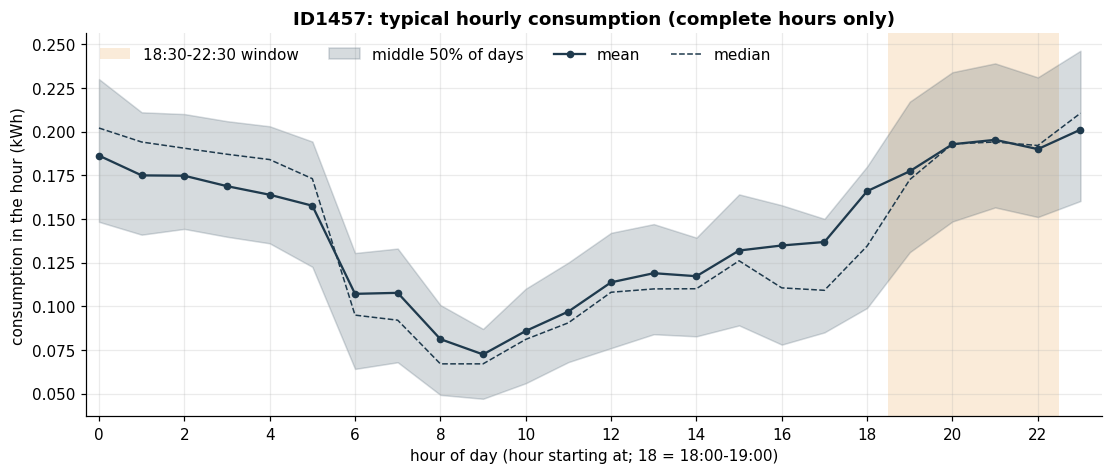

days contributing per hour: min 229, max 241
mean kWh in the hour starting at: {0: 0.186, 3: 0.169, 5: 0.158, 6: 0.107, 9: 0.072, 14: 0.117, 18: 0.166, 20: 0.193, 23: 0.201}


In [7]:
lvl = "typical"
hourly, daily = tables[lvl]["hourly"], tables[lvl]["daily"]
hp = hourly["kwh"].unstack("hour")                       # rows = day, columns = hour 0..23 (NaN unless 4 usable intervals)
q = hp.quantile([0.25, 0.5, 0.75]); mean = hp.mean(); n_days = hp.notna().sum()

fig, ax = plt.subplots(figsize=(10, 4.2))
ax.axvspan(18.5, 22.5, color=C_PEAK, alpha=0.18, lw=0, label="18:30-22:30 window")
ax.fill_between(q.columns, q.loc[0.25], q.loc[0.75], color=C_INK, alpha=0.18, label="middle 50% of days")
ax.plot(mean.index, mean, color=C_INK, marker="o", ms=4, label="mean")
ax.plot(q.columns, q.loc[0.5], color=C_INK, ls="--", lw=1, label="median")
ax.set_xticks(range(0, 24, 2)); ax.set_xlim(-0.3, 23.5)
ax.set_xlabel("hour of day (hour starting at; 18 = 18:00-19:00)"); ax.set_ylabel("consumption in the hour (kWh)")
ax.set_title(f"{HH[lvl]}: typical hourly consumption (complete hours only)")
ax.legend(ncol=4, loc="upper left"); save(fig, "02a_hourly_pattern"); plt.show()
print(f"days contributing per hour: min {n_days.min()}, max {n_days.max()}")
print("mean kWh in the hour starting at:", {int(h): round(float(mean[h]), 3) for h in [0, 3, 5, 6, 9, 14, 18, 20, 23]})

**Observed.** Average hourly use of ID1457 is lowest in the 09:00 hour (0.072 kWh), rises through the afternoon (0.117 kWh at 14:00, 0.166 kWh at 18:00), reaches about 0.19–0.20 kWh from 20:00 to midnight, and stays high overnight (0.186 kWh at 00:00, 0.158 kWh at 05:00), with a sharp step down between 05:00 and 06:00 (0.158 to 0.107 kWh). The window sits on the rising evening part of the day. The 18:00 hour is only half inside it, so hourly totals cannot reproduce the target and 15-minute data are needed. The register does not tell us *why* the profile has this shape.

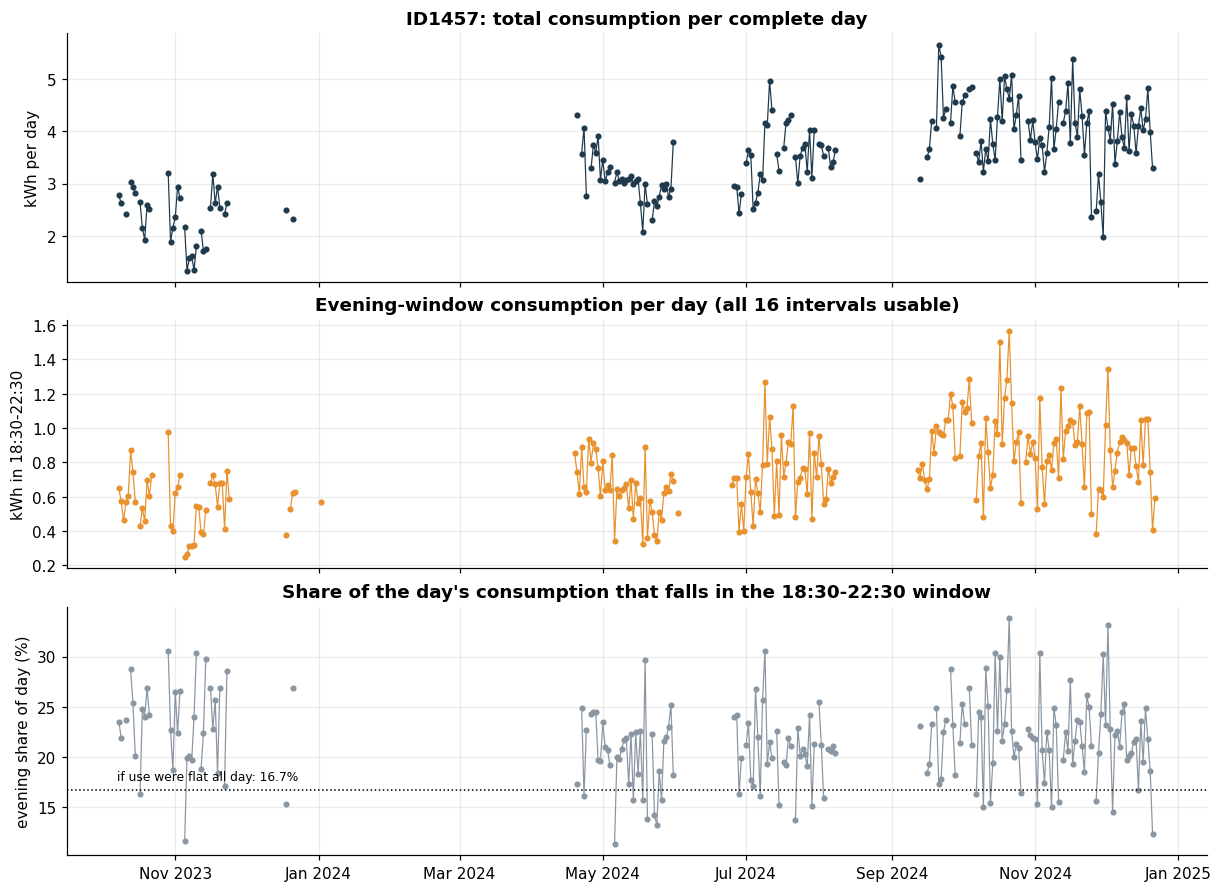

calendar days in this household's span: 444 | complete days: 200 | valid evening values: 231 | days with a total but no evening: 0
             mean   50%   min   max
total_kwh    3.48  3.53  1.33  5.66
evening_kwh  0.75  0.72  0.25  1.57
days with an evening share above 16.7%: 173 of 200
  mean daily total Oct-Dec 2023: 2.36 kWh over 35 complete days
  mean daily total Apr-Jul 2024: 3.29 kWh over 69 complete days
  mean daily total Sep-Dec 2024: 4.07 kWh over 89 complete days


In [8]:
lvl = "typical"
daily = tables[lvl]["daily"]
span = pd.date_range(daily.index.min(), daily.index.max(), freq="D")
daily = daily.reindex(span)
share = daily.evening_kwh / daily.total_kwh * 100

fig, ax = plt.subplots(3, 1, figsize=(11, 8), sharex=True)
ax[0].plot(daily.index, daily.total_kwh, marker="o", ms=3, lw=0.8, color=C_INK)
ax[0].set_ylabel("kWh per day"); ax[0].set_title(f"{HH[lvl]}: total consumption per complete day")
ax[1].plot(daily.index, daily.evening_kwh, marker="o", ms=3, lw=0.8, color=C_PEAK)
ax[1].set_ylabel("kWh in 18:30-22:30"); ax[1].set_title("Evening-window consumption per day (all 16 intervals usable)")
ax[2].plot(daily.index, share, marker="o", ms=3, lw=0.8, color=C_MUTED)
ax[2].axhline(100 * 4 / 24, color="k", ls=":", lw=1); ax[2].text(daily.index[0], 100 * 4 / 24 + 1, "if use were flat all day: 16.7%", fontsize=8)
ax[2].set_ylabel("evening share of day (%)"); ax[2].set_title("Share of the day's consumption that falls in the 18:30-22:30 window")
for a in ax:                                   # mark days with some data but not enough for a total
    a.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
save(fig, "02b_daily_and_evening"); plt.show()
n_span = len(span)
print(f"calendar days in this household's span: {n_span} | complete days: {int(daily.total_kwh.notna().sum())} | "
      f"valid evening values: {int(daily.evening_kwh.notna().sum())} | days with a total but no evening: "
      f"{int((daily.total_kwh.notna() & daily.evening_kwh.isna()).sum())}")
print(daily[['total_kwh','evening_kwh']].describe().round(2).T[['mean','50%','min','max']])
print(f"days with an evening share above 16.7%: {(share > 100*4/24).sum()} of {share.notna().sum()}")
for lab, a, b in [("Oct-Dec 2023", "2023-10-01", "2023-12-31"), ("Apr-Jul 2024", "2024-04-01", "2024-07-31"), ("Sep-Dec 2024", "2024-09-01", "2024-12-31")]:
    x = daily.loc[a:b, "total_kwh"].dropna(); print(f"  mean daily total {lab}: {x.mean():.2f} kWh over {len(x)} complete days")

**Observed.** A break in a line is a day with at least one missing interval; it is not drawn as zero.
* Complete days exist in a few blocks (Oct–Dec 2023, Apr–Jul 2024, Sep–Dec 2024): 200 of 444 calendar days.
* Daily use varies a lot (1.3 to 5.7 kWh) and drifts upward: the mean complete day uses 2.36 kWh (Oct–Dec 2023), 3.29 kWh (Apr–Jul 2024) and 4.07 kWh (Sep–Dec 2024). The readings cannot tell whether this is season, new equipment or occupancy.
* The evening window holds more than its flat-day share (16.7%) on 173 of 200 days.

## 3. Three households with different levels

We compare the low, typical and high households, using complete days only. The left panel shows absolute kWh per 15-minute interval. The right panel divides each day by its own total, so it shows the *shape* of the day regardless of level.

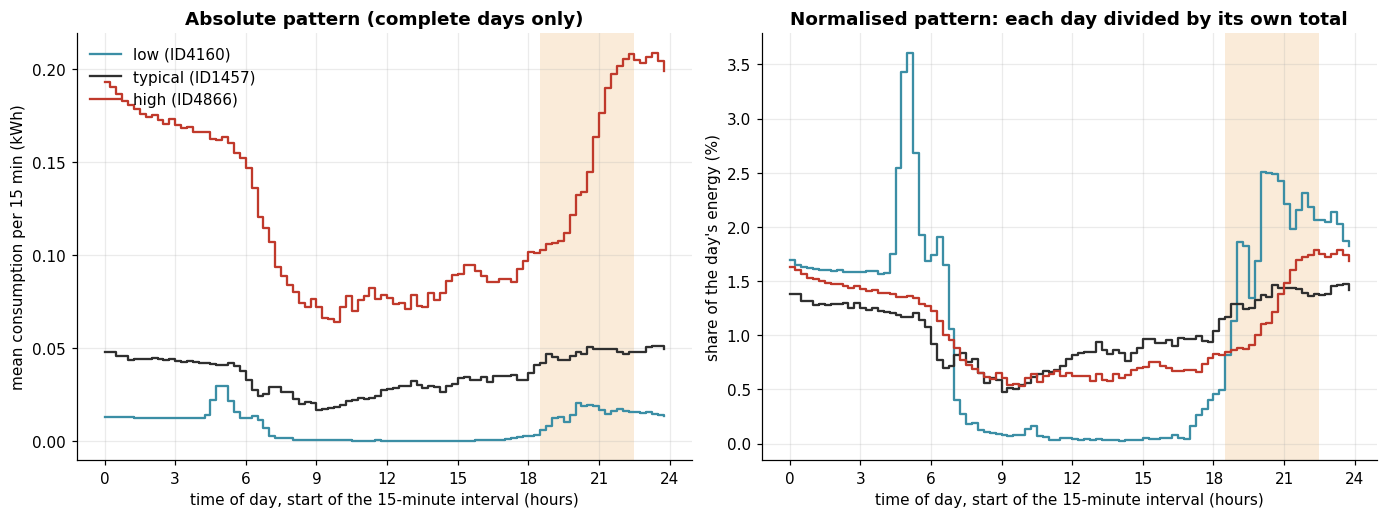

,household,complete_days,mean_daily_kwh,mean_evening_kwh,complete_days_with_zero_total_%,evening_share_%_(days_with_use),intervals_exactly_zero_%,evening_values_exactly_zero_%,share_of_day_08-17_%,share_of_day_18:30-22:30_%,busiest_interval_starts_at
level,,,,,,,,,,,
low,ID4160,203,0.76,0.24,33.0,31.48,70.57,47.78,2.16,31.48,04:45
typical,ID1457,200,3.48,0.75,0.0,21.63,1.46,0.00,27.50,21.63,23:15
high,ID4866,199,12.04,2.41,0.0,20.22,0.04,0.00,22.95,20.22,23:15


In [9]:
prof, prof_share, comp_rows = {}, {}, []
for lvl in ["low", "typical", "high"]:
    g = grids[lvl]; daily = tables[lvl]["daily"]
    full_days = daily.index[daily.n_ok == 96]
    m = g[g.day.isin(full_days)].pivot_table(index="day", columns="start_tod", values="kwh_ok")
    prof[lvl] = m                                   # rows: complete days, columns: 96 interval starts
    prof_share[lvl] = m.div(m.sum(axis=1), axis=0) * 100
    d_ev = daily.dropna(subset=["total_kwh", "evening_kwh"])
    comp_rows.append({"level": lvl, "household": HH[lvl], "complete_days": len(full_days),
                      "mean_daily_kwh": daily.total_kwh.mean(), "mean_evening_kwh": d_ev.evening_kwh.mean(),
                      "complete_days_with_zero_total_%": (daily.total_kwh.dropna() == 0).mean() * 100,
                      "evening_share_%_(days_with_use)": (d_ev.evening_kwh / d_ev.total_kwh).mean() * 100,
                      "intervals_exactly_zero_%": (m == 0).stack().mean() * 100,
                      "evening_values_exactly_zero_%": (d_ev.evening_kwh == 0).mean() * 100,
                      "share_of_day_08-17_%": prof_share[lvl].loc[:, (prof_share[lvl].columns >= pd.Timedelta(hours=8)) & (prof_share[lvl].columns < pd.Timedelta(hours=17))].sum(axis=1, min_count=1).mean(),
                      "share_of_day_18:30-22:30_%": prof_share[lvl].loc[:, (prof_share[lvl].columns >= PEAK_START) & (prof_share[lvl].columns < PEAK_END)].sum(axis=1, min_count=1).mean(),
                      "busiest_interval_starts_at": str(prof[lvl].mean().idxmax()).split(" days ")[-1][:5]})
tod = (prof["typical"].columns / pd.Timedelta(hours=1)).to_numpy()

fig, ax = plt.subplots(1, 2, figsize=(12.5, 4.6), sharex=True)
for lvl in prof:
    ax[0].plot(tod, prof[lvl].mean(), drawstyle="steps-post", color=C_HH[lvl], label=f"{lvl} ({HH[lvl]})")
    ax[1].plot(tod, prof_share[lvl].mean(), drawstyle="steps-post", color=C_HH[lvl], label=lvl)
for a in ax:
    a.axvspan(18.5, 22.5, color=C_PEAK, alpha=0.18, lw=0); a.set_xticks(range(0, 25, 3))
    a.set_xlabel("time of day, start of the 15-minute interval (hours)")
ax[0].set_ylabel("mean consumption per 15 min (kWh)"); ax[0].set_title("Absolute pattern (complete days only)"); ax[0].legend(loc="upper left")
ax[1].set_ylabel("share of the day's energy (%)"); ax[1].set_title("Normalised pattern: each day divided by its own total")
save(fig, "03_three_households"); plt.show()
display(pd.DataFrame(comp_rows).set_index("level").round(2))

**Observed.**
* **Level differs by a factor of about 16:** mean daily use is 0.76, 3.48 and 12.04 kWh (low, typical, high); evening-window use is 0.24, 0.75 and 2.41 kWh.
* **The low household is mostly zero.** 70.6% of its intervals are exactly 0.000 kWh and 33% of its complete days have a zero total. When it does draw, it does so in two bursts (about 04:45–06:30 and the evening; 31.5% of its non-zero days' energy falls in 18:30–22:30).
* **The typical and high households have a similar shape:** use falls around 06:00–08:00, stays low during the day and is highest at night (the busiest interval starts at 23:15, after the window ends). Their share of energy inside the window is 21.6% and 20.2% (flat day: 16.7%).

The data hold one register per household, so they cannot explain these shapes. The safe lesson is that a single global daily shape will not fit everyone: a model needs each household's own level and rhythm.

## 4. Missing data

### 4a. Availability across the day and across dates (one household)
Each row is a date and each column a quarter-hour. A dark cell means a reading exists.

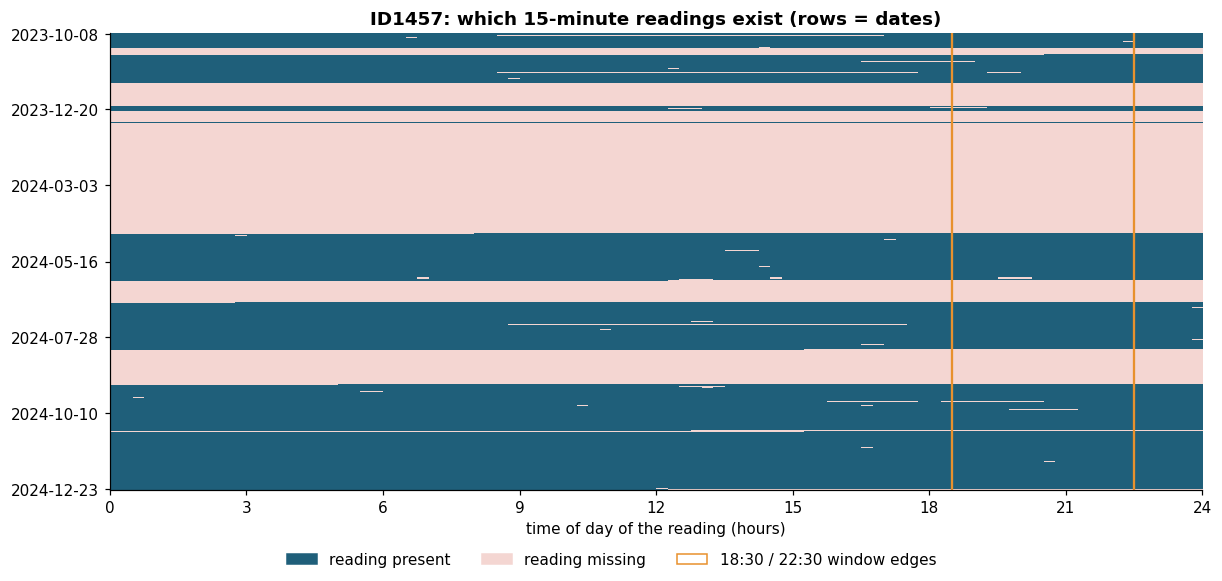

low      ID4160: 21,674 of 40,512 readings exist (53.5%) | dates in span: 422 -> fully empty 191, partly filled 27, fully populated 204 | 97% of all missing readings fall on fully empty dates | longest run of empty dates: 120 days
typical  ID1457: 22,855 of 42,528 readings exist (53.7%) | dates in span: 443 -> fully empty 199, partly filled 41, fully populated 203 | 97% of all missing readings fall on fully empty dates | longest run of empty dates: 107 days
high     ID4866: 22,040 of 40,512 readings exist (54.4%) | dates in span: 422 -> fully empty 173, partly filled 47, fully populated 202 | 90% of all missing readings fall on fully empty dates | longest run of empty dates: 85 days


In [10]:
lvl = "typical"
g = grids[lvl]
avail = g.present.iloc[:-1].copy()                      # drop the extra 24:00 point
M = avail.groupby([avail.index.normalize(), avail.index.time]).first().unstack()
M = M.reindex(columns=sorted(M.columns))
cmap = ListedColormap(["#f4d6d2", "#1f5f7a"])

fig, ax = plt.subplots(figsize=(11, 5.2))
x0, x1 = 0, 24
ax.imshow(M.values.astype(float), aspect="auto", cmap=cmap, interpolation="nearest",
          extent=[x0, x1, len(M), 0], vmin=0, vmax=1)
for h in (18.5, 22.5):
    ax.axvline(h, color=C_PEAK, lw=1.5)
ax.set_xticks(range(0, 25, 3)); ax.set_xlabel("time of day of the reading (hours)")
yt = np.linspace(0, len(M) - 1, 7).astype(int)
ax.set_yticks(yt + 0.5); ax.set_yticklabels([str(M.index[i].date()) for i in yt]); ax.grid(False)
ax.set_title(f"{HH[lvl]}: which 15-minute readings exist (rows = dates)")
fig.legend(handles=[Patch(color="#1f5f7a", label="reading present"), Patch(color="#f4d6d2", label="reading missing"),
                    Patch(facecolor="none", edgecolor=C_PEAK, label="18:30 / 22:30 window edges")],
           loc="outside lower center", ncol=3)
save(fig, "04a_availability_one_household"); plt.show()
exp, have = M.size, int(M.values.sum())
for L, G in grids.items():
    av = G.present.iloc[:-1]; per_day = av.groupby(av.index.normalize()).sum()
    empty = per_day == 0; longest = int(empty.groupby((~empty).cumsum()).cumsum().max())
    print(f"{L:8s} {HH[L]}: {int(av.sum()):,} of {len(av):,} readings exist ({100*av.mean():.1f}%) | dates in span: {len(per_day)} -> "
          f"fully empty {(per_day==0).sum()}, partly filled {((per_day>0)&(per_day<96)).sum()}, fully populated {(per_day==96).sum()} | "
          f"{100*(96*(per_day==0).sum())/(len(av)-av.sum()):.0f}% of all missing readings fall on fully empty dates | longest run of empty dates: {longest} days")

**Observed.** Missing data comes mostly in **whole days**: of 443 dates in the household's span, 203 are fully populated, 199 are completely empty and only 41 are partly filled. 97% of its missing readings lie on empty dates (97% for the low and 90% for the high household). The longest empty run is 107 days (3 January to 18 April 2024; 120 and 85 days for the low and high households). A feature such as "yesterday's evening" exists only if yesterday's readings do. The chart shows where data are missing, not why.

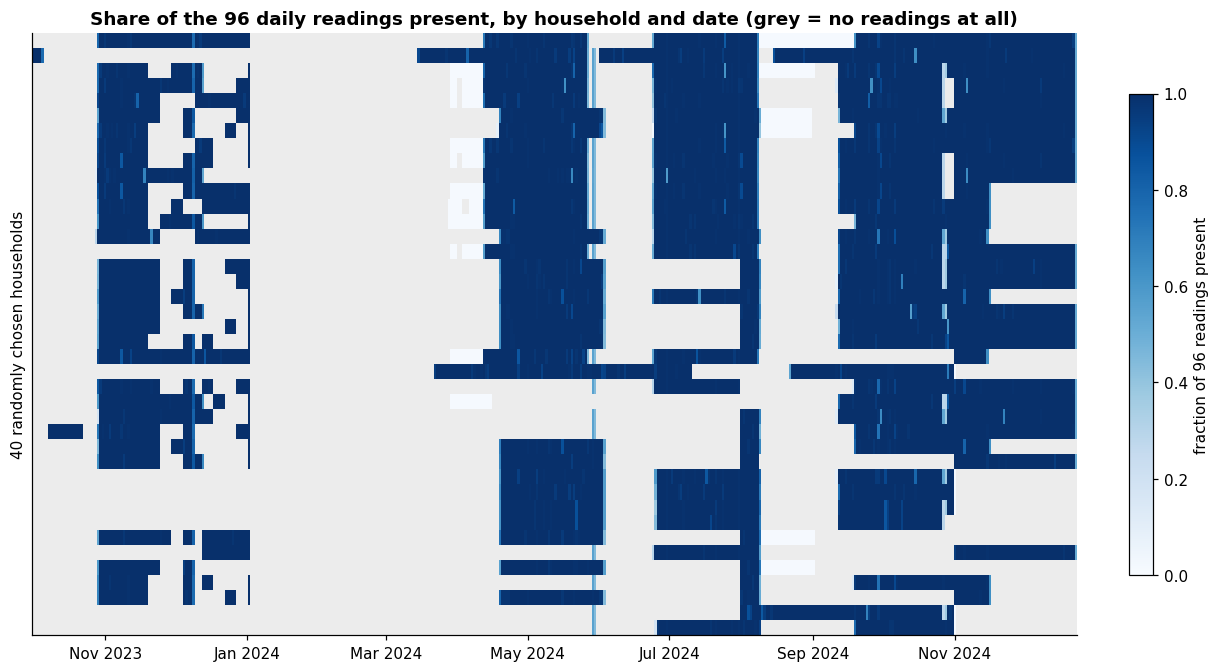

dates on which fewer than 25% of the busiest day's 2,646 households have any reading:
   01 Oct 2023 to 28 Oct 2023 (28 days)
   03 Jan 2024 to 28 Mar 2024 (86 days)
   01 Apr 2024 to 02 Apr 2024 (2 days)
   04 Jun 2024 to 23 Jun 2024 (20 days)
   10 Aug 2024 to 11 Sep 2024 (33 days)
audit, all households: 52,681,065 of 98,294,338 quarter-hour slots inside household spans are missing (53.6%)


In [11]:
# 4b. Availability for many households over the whole period (from the audited per-day table, no raw rows needed)
rng = np.random.default_rng(42)
hs = stats.index[stats.days_with_any_reading >= 60].to_numpy()
pick = np.sort(rng.choice(hs, size=40, replace=False))
sub = hd[hd.household_ID.isin(pick)].copy()
sub["date"] = pd.to_datetime(sub["date"])
cover = sub.pivot(index="household_ID", columns="date", values="n_readings_day") / 96
cover = cover.reindex(columns=pd.date_range(hd["date"].min(), hd["date"].max()))
order = cover.notna().sum(axis=1).sort_values(ascending=False).index
cover = cover.loc[order]

fig, ax = plt.subplots(figsize=(11, 6))
cm = plt.get_cmap("Blues").copy(); cm.set_bad("#ececec")
im = ax.imshow(cover.values, aspect="auto", cmap=cm, vmin=0, vmax=1, interpolation="nearest")
ticks = [i for i, d in enumerate(cover.columns) if d.day == 1 and d.month % 2 == 1]
ax.set_xticks(ticks); ax.set_xticklabels([cover.columns[i].strftime("%b %Y") for i in ticks])
ax.set_yticks([]); ax.set_ylabel("40 randomly chosen households"); ax.grid(False)
ax.set_title("Share of the 96 daily readings present, by household and date (grey = no readings at all)")
fig.colorbar(im, ax=ax, label="fraction of 96 readings present", shrink=0.8)
save(fig, "04b_availability_many_households"); plt.show()
n_hh = hd.assign(d=pd.to_datetime(hd["date"])).groupby("d")["household_ID"].nunique()
n_hh = n_hh.reindex(pd.date_range(n_hh.index.min(), n_hh.index.max()), fill_value=0)
quiet = pd.Series(n_hh.index[n_hh < 0.25 * n_hh.max()])
runs = quiet.groupby((quiet.diff() != pd.Timedelta(days=1)).cumsum()).agg(["min", "max", "size"])
print(f"dates on which fewer than 25% of the busiest day's {n_hh.max():,} households have any reading:")
for _, r_ in runs.iterrows():
    print(f"   {r_['min']:%d %b %Y} to {r_['max']:%d %b %Y} ({int(r_['size'])} days)")
rep = json.load(open(AUDIT_DIR / "audit_report.json"))
print(f"audit, all households: {rep['span']['missing_slots_within_span']:,} of {rep['span']['expected_slots_within_span']:,} "
      f"quarter-hour slots inside household spans are missing ({100*rep['span']['missing_slots_within_span']/rep['span']['expected_slots_within_span']:.1f}%)")

**Observed.** One row per household (40 random ones with at least 60 days), one column per day, coloured by the share of the 96 daily readings that exist. The gaps are largely **shared across households**: fewer than a quarter of the busiest day's households report at all in the first four weeks of October 2023, 3 January to 28 March 2024, 1–2 April 2024, 4–23 June 2024 and 10 August to 11 September 2024. Overall the audit counted 53.6% of quarter-hour slots inside household spans as missing. Because the blocks line up across households, they look like collection outages rather than household behaviour (an interpretation, not verified here).

### 4c. A missing reading versus a genuine zero

The left panels show a window around a **missing reading**; the right panels show a stretch where the register did not change, i.e. **real zero consumption**. A gap is *unknown*; a flat register is *known to be zero*.

missing-reading example: typical ID1457 2023-10-22 14:15:00 | zero-consumption example: low ID4160 2023-10-29 06:30:00


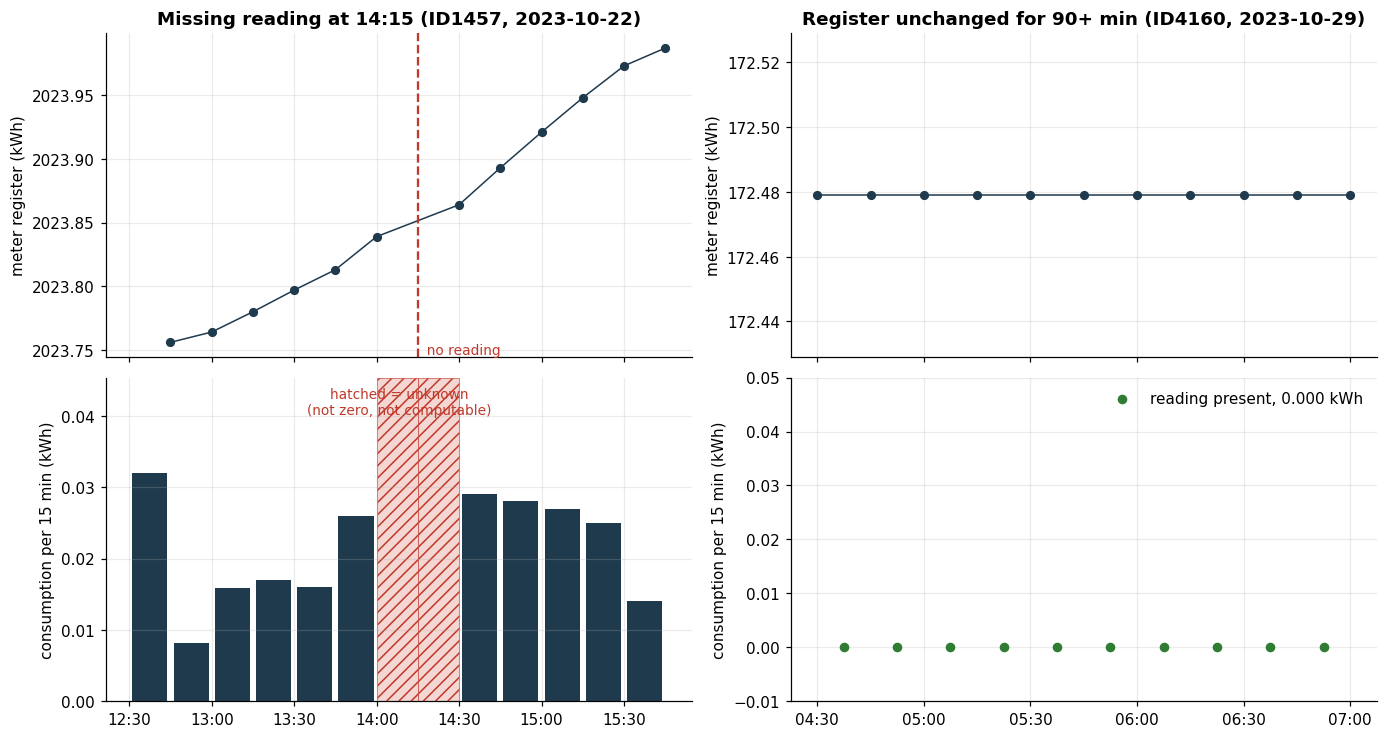

In [12]:
def find_missing_example(g, hour_from=8, hour_to=21):
    # an isolated missing reading whose neighbours exist, with a few good readings on each side
    p = g.present
    iso = (~p) & p.shift(1, fill_value=False) & p.shift(-1, fill_value=False)
    for t in g.index[iso]:
        w = g.loc[t - 6 * INTERVAL: t + 6 * INTERVAL]
        if hour_from <= t.hour <= hour_to and w.present.sum() == 12 and (w.kwh.dropna() >= 0).all():
            return t
    return None

def find_zero_example(g):
    z = (g.kwh == 0)
    run = z.astype(int).rolling(6).sum() == 6                        # six exact-zero intervals in a row, all readings present
    for t in g.index[run]:
        w = g.loc[t - 8 * INTERVAL: t + 2 * INTERVAL]
        if w.present.all() and (w.kwh.dropna() >= 0).all():
            return t
    return None

miss_lvl, t_miss = None, None
for lvl in ["typical", "high", "low"]:
    t_miss = find_missing_example(grids[lvl])
    if t_miss is not None:
        miss_lvl = lvl; break
zero_lvl, t_zero = None, None
for lvl in ["low", "typical", "high"]:
    t_zero = find_zero_example(grids[lvl])
    if t_zero is not None:
        zero_lvl = lvl; break
print("missing-reading example:", miss_lvl, HH.get(miss_lvl), t_miss, "| zero-consumption example:", zero_lvl, HH.get(zero_lvl), t_zero)

fig, ax = plt.subplots(2, 2, figsize=(12.5, 6.6), sharex="col")
def panel(col, g, centre, before, after, title):
    w = g.loc[centre - before * INTERVAL: centre + after * INTERVAL]
    ax[0, col].plot(w.index[w.present], w.reg[w.present], marker="o", ms=5, lw=1, color=C_INK)
    ax[0, col].set_ylabel("meter register (kWh)"); ax[0, col].set_title(title)
    ax[0, col].yaxis.set_major_formatter(plt.ScalarFormatter(useOffset=False))
    ax[1, col].bar(w.index[w.usable] - INTERVAL / 2, w.kwh_ok[w.usable], width=INTERVAL * 0.85, color=C_INK)
    ax[1, col].set_ylabel("consumption per 15 min (kWh)")
    ax[1, col].xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
    return w

if t_miss is not None:
    w = panel(0, grids[miss_lvl], t_miss, 6, 6, f"Missing reading at {t_miss:%H:%M} ({HH[miss_lvl]}, {t_miss.date()})")
    ax[0, 0].axvline(t_miss, color="#c0392b", ls="--"); ax[0, 0].text(t_miss, ax[0, 0].get_ylim()[0], "  no reading", color="#c0392b", va="bottom", fontsize=9)
    lost = w.index[(~w.usable) & (w.index > w.index[0])]
    for t in lost:
        ax[1, 0].axvspan(t - INTERVAL, t, facecolor="#f4d6d2", hatch="///", edgecolor="#c0392b", lw=0.4)
    ax[1, 0].set_ylim(0, ax[1, 0].get_ylim()[1] * 1.35)
    ax[1, 0].text(0.5, 0.97, "hatched = unknown\n(not zero, not computable)", transform=ax[1, 0].transAxes, ha="center", va="top", fontsize=9, color="#c0392b")
if t_zero is not None:
    w = panel(1, grids[zero_lvl], t_zero, 8, 2, f"Register unchanged for 90+ min ({HH[zero_lvl]}, {t_zero.date()})")
    z = w.index[w.kwh == 0]
    ax[1, 1].scatter(z - INTERVAL / 2, np.zeros(len(z)), color="#2e7d32", zorder=3, s=28, label="reading present, 0.000 kWh")
    v0 = float(w.reg.iloc[0]); ax[0, 1].set_ylim(v0 - 0.05, v0 + 0.05)
    ax[1, 1].legend(loc="upper right"); ax[1, 1].set_ylim(-0.01, max(0.05, float(w.kwh_ok.max()) * 1.3 if w.kwh_ok.notna().any() else 0.05))
save(fig, "04c_missing_vs_zero"); plt.show()

In [13]:
rows = []
for lvl, g in grids.items():
    comp = g.kwh.notna()
    span_n = len(g) - 1
    rows.append({"level": lvl, "household": HH[lvl], "intervals_in_span": span_n,
                 "computable_%": 100 * comp.sum() / span_n,
                 "unknown_(missing)_%": 100 * (~comp).sum() / span_n,
                 "exactly_zero_%_of_computable": 100 * (g.kwh == 0).sum() / comp.sum(),
                 "negative_steps": int((g.kwh < 0).sum())})
display(pd.DataFrame(rows).set_index("level").round(2))

,household,intervals_in_span,computable_%,unknown_(missing)_%,exactly_zero_%_of_computable,negative_steps
level,,,,,,
low,ID4160,40512,53.44,46.56,69.56,0
typical,ID1457,42528,53.64,46.37,1.46,0
high,ID4866,40512,54.27,45.73,0.03,0


**Observed.**
* One missing reading removes two intervals (the one ending at it and the one starting at it). The register still carries its running total, so the *sum* of the two intervals is known, but not how it split. The project asks for all 17 readings so that nothing inside the window is hidden.
* Treating a gap as 0 kWh would invent a quiet evening and pull averages down. In the table, about 46% of each household's intervals are unknown, while the share of *known* intervals that are exactly zero is 69.6% (low), 1.5% (typical) and 0.03% (high).
* A flat register could mean an empty home or a stalled meter; the readings cannot tell.

## 5. The evening target in the audited data

`peakwise_target_clean.csv` holds the audited evening energy (kWh, 18:30–22:30) for every household-day that passed all rules. We use it directly and do not rebuild it. Dividing by 4 hours gives the average power in kW.

464,640 valid household-days | 2,931 households | mean 1.383 kWh | median 0.721 kWh | max 122.95 kWh
exactly 0 kWh: 37,219 days (8.0%)
smallest non-zero value: 0.001 kWh | values <= 0.01 kWh: 40,555 (8.7%)


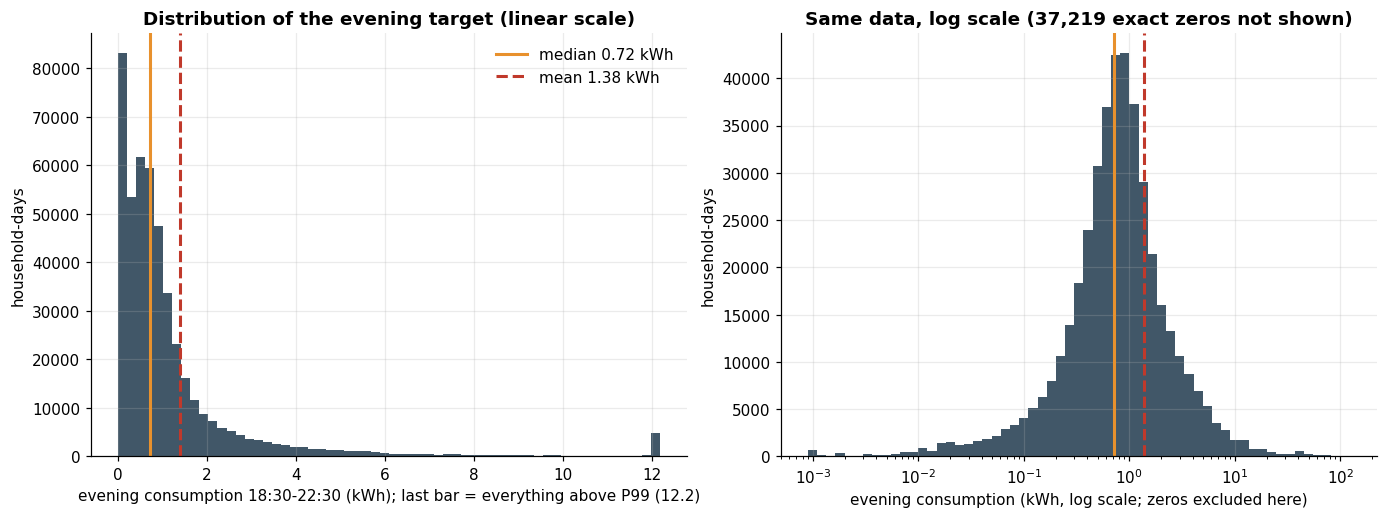

In [14]:
target = read_audit_csv(AUDIT_DIR / "peakwise_target_clean.csv")
y = target["peak_kwh_1830_2230"]
mean_, med_ = y.mean(), y.median()
qs = y.quantile([0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99])
print(f"{len(y):,} valid household-days | {target.household_ID.nunique():,} households | mean {mean_:.3f} kWh | median {med_:.3f} kWh | max {y.max():.2f} kWh")
print(f"exactly 0 kWh: {(y == 0).sum():,} days ({100*(y==0).mean():.1f}%)")

fig, ax = plt.subplots(1, 2, figsize=(12.5, 4.6))
hi = qs.loc[0.99]
ax[0].hist(y.clip(upper=hi), bins=60, color=C_INK, alpha=0.85)
ax[0].axvline(med_, color=C_PEAK, lw=2, label=f"median {med_:.2f} kWh")
ax[0].axvline(mean_, color="#c0392b", lw=2, ls="--", label=f"mean {mean_:.2f} kWh")
ax[0].set_xlabel(f"evening consumption 18:30-22:30 (kWh); last bar = everything above P99 ({hi:.1f})")
ax[0].set_ylabel("household-days"); ax[0].set_title("Distribution of the evening target (linear scale)"); ax[0].legend()
pos = y[y > 0]
print(f"smallest non-zero value: {pos.min():.3f} kWh | values <= 0.01 kWh: {(y <= 0.01).sum():,} ({100*(y <= 0.01).mean():.1f}%)")
bins = np.logspace(np.log10(pos.min()), np.log10(pos.max()), 60)
ax[1].hist(pos, bins=bins, color=C_INK, alpha=0.85); ax[1].set_xscale("log")
ax[1].axvline(med_, color=C_PEAK, lw=2); ax[1].axvline(mean_, color="#c0392b", lw=2, ls="--")
ax[1].set_xlabel("evening consumption (kWh, log scale; zeros excluded here)"); ax[1].set_ylabel("household-days")
ax[1].set_title(f"Same data, log scale ({(y==0).sum():,} exact zeros not shown)")
save(fig, "05a_target_distribution"); plt.show()

**Observed.** 464,640 valid household-days from 2,931 households. The median is 0.72 kWh and the mean 1.38 kWh, almost twice as large, because a few very large days pull the mean up. 37,219 days (8.0%) are exactly 0.000 kWh with all 17 readings present; the smallest non-zero value is 0.001 kWh, the register's resolution. The distribution is strongly right-skewed, so one "average evening" is a poor summary and squared-error metrics will be dominated by a few large days.

,household_days,share_%,kWh from,kWh to,avg power over 4 h (kW) at top of band
peak_kwh_1830_2230,,,,,
exactly zero,37219,8.010,NaN,0.000,0.000
very low (<= P10),9252,1.991,0.000,0.030,0.007
low (P10-P25),69690,14.999,0.030,0.334,0.083
typical (P25-P75),232324,50.001,0.334,1.292,0.323
high (P75-P95),92924,19.999,1.292,4.379,1.095
very high (P95-P99),18585,4.000,4.379,12.171,3.043
unusually high (> P99),4646,1.000,12.171,122.950,30.738



quantiles of the target (kWh):
0.01     0.000
0.05     0.000
0.10     0.030
0.25     0.334
0.50     0.721
0.75     1.292
0.90     2.674
0.95     4.379
0.99    12.171


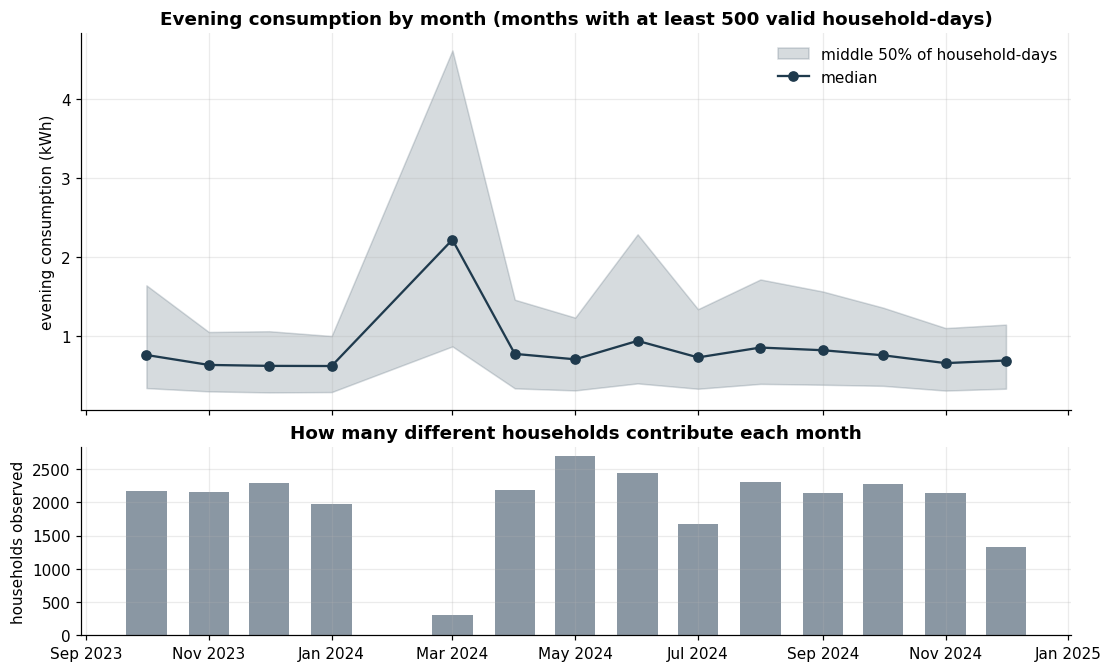

month        2023-10    2023-11    2023-12  2024-01  2024-03    2024-04    2024-05    2024-06    2024-07    2024-08   2024-09    2024-10    2024-11   2024-12
n           10963.00  51849.000  30020.000  2817.00  3282.00  32997.000  60923.000  19260.000  50272.000  20468.000  40350.00  61979.000  50457.000  29003.00
median          0.76      0.634      0.622     0.62     2.22      0.774      0.705      0.939      0.729      0.854      0.82      0.756      0.657      0.69
households   2179.00   2158.000   2299.000  1979.00   304.00   2186.000   2696.000   2448.000   1676.000   2310.000   2144.00   2274.000   2140.000   1325.00


In [15]:
bands = pd.cut(y, bins=[-np.inf, 0, qs.loc[0.10], qs.loc[0.25], qs.loc[0.75], qs.loc[0.95], qs.loc[0.99], np.inf],
               labels=["exactly zero", "very low (<= P10)", "low (P10-P25)", "typical (P25-P75)",
                       "high (P75-P95)", "very high (P95-P99)", "unusually high (> P99)"])
bt = bands.value_counts().sort_index().to_frame("household_days")
bt["share_%"] = 100 * bt.household_days / len(y)
lo = [np.nan, 0, qs.loc[0.10], qs.loc[0.25], qs.loc[0.75], qs.loc[0.95], qs.loc[0.99]]
hi_ = [0, qs.loc[0.10], qs.loc[0.25], qs.loc[0.75], qs.loc[0.95], qs.loc[0.99], y.max()]
bt["kWh from"] = lo; bt["kWh to"] = hi_
bt["avg power over 4 h (kW) at top of band"] = bt["kWh to"] / 4
display(bt.round(3))
print("\nquantiles of the target (kWh):"); print(qs.round(3).to_string())

target["month"] = pd.to_datetime(target["date"]).dt.to_period("M")
m = target.groupby("month")["peak_kwh_1830_2230"].agg(n="size", median="median", q25=lambda s: s.quantile(.25), q75=lambda s: s.quantile(.75))
m = m[m.n >= 500]
hh_m = target.groupby("month")["household_ID"].nunique().reindex(m.index)
fig, ax = plt.subplots(2, 1, figsize=(10, 6), sharex=True, height_ratios=[2, 1])
xm = m.index.to_timestamp()
ax[0].fill_between(xm, m.q25, m.q75, color=C_INK, alpha=0.18, label="middle 50% of household-days")
ax[0].plot(xm, m["median"], marker="o", color=C_INK, label="median")
ax[0].set_ylabel("evening consumption (kWh)"); ax[0].set_title("Evening consumption by month (months with at least 500 valid household-days)")
ax[0].legend()
ax[1].bar(xm, hh_m.values, width=20, color=C_MUTED); ax[1].set_ylabel("households observed")
ax[1].set_title("How many different households contribute each month")
ax[1].xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
save(fig, "05b_target_by_month"); plt.show()
print(pd.concat([m[["n", "median"]], hh_m.rename("households")], axis=1).round(3).T.to_string())

**Observed.**
* "Typical" (P25 to P75) is 0.33 to 1.29 kWh (about 0.08–0.32 kW average), and half of all days fall in this band.
* Above the 99th percentile (12.17 kWh, 3.0 kW average) there are 4,646 days. The maximum, 122.95 kWh, would be an average of 30.7 kW for four hours. These days pass every audit rule but look extreme for a household and deserve a separate check.
* Monthly medians are 0.62–0.94 kWh except **March 2024 (2.22 kWh)**, which also has by far the fewest households (304 instead of about 1,300–2,700). Each month contains a different set of households, so this chart says nothing about seasonality.

In [16]:
# Cross-check: our own interval arithmetic reproduces the audited evening values for the three households.
chk = []
t_idx = target.assign(date=pd.to_datetime(target["date"])).set_index(["household_ID", "date"])["peak_kwh_1830_2230"]
for lvl, hid in HH.items():
    mine = tables[lvl]["daily"]["evening_kwh"].dropna()
    audited = t_idx.xs(hid, level="household_ID")
    j = pd.concat([mine.rename("notebook"), audited.rename("audited")], axis=1, join="inner")
    chk.append({"household": hid, "days_in_both": len(j), "max_abs_difference_kwh": float((j.notebook - j.audited).abs().max()),
                "days_notebook_only": int(mine.index.difference(audited.index).size),
                "days_audited_only": int(audited.index.difference(mine.index).size)})
display(pd.DataFrame(chk).set_index("household"))

,days_in_both,max_abs_difference_kwh,days_notebook_only,days_audited_only
household,,,,
ID4160,221,4.640732e-14,0,0
ID1457,231,3.747003e-13,0,0
ID4866,227,3.114176e-12,0,0


**Observed.** A consistency check, not a finding. For all 679 household-days that exist in both, the evening values computed here from the raw readings agree with the audited file to about 10⁻¹² kWh (rounding), and no day exists in only one of them. So the interval arithmetic and the window (18:30–22:30, 17 readings) used here are the same as in the audit.

## 6. Summary

| # | Observation | Status |
|---|---|---|
| 1 | **The register is a running total and the target is a difference of two readings.** For ID1457 on 14 Oct 2024 the register is about 3,175 kWh but the day uses 3.76 kWh; the evening is `R(22:30) − R(18:30)` = 0.728 kWh. The audited target is reproduced for all 679 household-days of the three households to about 10⁻¹² kWh. | Verified |
| 2 | **Missing data is common and mostly whole days.** About 54% of quarter-hours exist; 90–97% of the missing readings lie on empty dates, and the gaps are largely shared across households. | Verified for these households and the 40 sampled |
| 3 | **Households differ in level and in rhythm.** Mean daily use is 0.76 / 3.48 / 12.04 kWh (about 16×); the typical and high households use most energy around 23:15, after the window closes. | Verified |
| 4 | **The target is skewed with many exact zeros.** Median 0.72 vs mean 1.38 kWh; 8.0% of valid days are exactly 0; the top 1% start at 12 kWh and reach 123 kWh. | Verified |
| 5 | **Levels and the observed population change over time.** ID1457 rises from 2.36 to 4.07 kWh per day; March 2024 has 304 households and a median of 2.22 kWh. | Numbers verified; causes unknown |

**Interpretation, not observation.** The gap blocks look like collection outages. Exact zeros could mean an empty home, self-supply or a stalled meter. The drift and the March 2024 jump could come from season, equipment, occupancy or *which* households were observed. The three households are chosen examples, not a random sample.

**Questions for the next notebook**
1. Which lag features will actually exist, given the whole-day gaps, and how many training rows survive?
2. Are the exact zeros and extreme days real behaviour a model should predict?
3. Which time-ordered split gives an honest estimate when shared outages and the household mix change by month?